# Challenge · swiss-forecast

*Book 21 · Time Series · Shelf V -- the book's closing challenge*

**The question.** Every night at midnight, how well can we forecast the next 24 hours of
electricity drawn in the city of Zurich?

**The number.** Mean absolute error in MW over a full year that no model has seen and no choice
was tuned on -- for three models, against the seasonal-naive baseline "the same day last week".

**The rules** (chapters 5 and 6): fit only on the past; every feature known at the previous
midnight; the test year is the last 365 days of the data; the models and their settings are the
ones chapter 6 chose on the validation year before it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

from ds_toolbox import evaluation as ev
from ds_toolbox import features as ft
from ds_toolbox import forecasting as fc
from ds_toolbox import io, tracking, viz

viz.use_style()

raw = io.load_sample("ewz_zurich_hourly.csv.gz")
hourly = raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
grid = ft.to_local_days(hourly)
holidays = ft.swiss_holidays(range(grid.index.year.min(), grid.index.year.max() + 1))
test_start = grid.index[-365]
test = grid[grid.index >= test_start]
print("train:", grid.index[0].date(), "->", (test_start - pd.Timedelta(days=1)).date(),
      "| test:", test_start.date(), "->", grid.index[-1].date(), f"({len(test)} days)")

train: 2017-01-01 -> 2025-11-08 | test: 2025-11-09 -> 2026-11-08 (365 days)


## 1 · The baseline: the same day last week

In [2]:
preds = {"seasonal naive (last week)": grid.shift(7).loc[test.index].to_numpy()}

## 2 · SARIMA on the daily mean, spread over the hours

The classical entry: chapter 4's SARIMA forecasts tomorrow's *daily mean* from the two years
before, refitted every week of the test year, and last week's hourly *shape* spreads it over the
24 hours. It is the classical model given a fair chance at the hourly task.

In [3]:
daily_mean = grid.mean(axis=1).asfreq("D")
shape = grid.div(grid.mean(axis=1), axis=0)
sarima_daily = pd.Series(index=test.index, dtype=float)
for start in range(0, len(test), 7):
    origin = test.index[start]
    hist = daily_mean[daily_mean.index < origin].iloc[-730:]
    fit = SARIMAX(hist, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
    steps = min(7, len(test) - start)
    # each day of the week is forecast from the same weekly origin: 1 to 7 days ahead
    sarima_daily.iloc[start:start + steps] = fit.forecast(steps).to_numpy()
preds["SARIMA × last week's shape"] = (shape.shift(7).loc[test.index].to_numpy()
                                       * sarima_daily.to_numpy()[:, None])

Note the handicap: within each week the SARIMA forecast is made up to 7 days ahead, while the
other models always forecast one day ahead. Refitting daily costs 365 fits; the weekly refit is
the honest cheap version, and it is said here rather than hidden.

## 3 · Gradient boosting on lag and calendar features (chapter 6)

In [4]:
X, y = fc.day_ahead_table(grid, holidays)
in_test = X.index >= test_start
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)
gbm.fit(X[~in_test], y[~in_test])
gbm_pred = pd.Series(gbm.predict(X[in_test]), index=X.index[in_test])
preds["gradient boosting"] = gbm_pred.to_numpy().reshape(len(test), 24)

## 4 · The temporal CNN (chapter 6)

In [5]:
w = fc.cnn_windows(grid, holidays)
dates = pd.DatetimeIndex(w["dates"])
train_w = {k: v[dates < test_start] for k, v in w.items()}
test_w = {k: v[dates >= test_start] for k, v in w.items()}
cnn = fc.CNNForecaster(epochs=80, val_days=180, patience=12, seed=0).fit(train_w)
preds["temporal CNN"] = cnn.predict(test_w)
assert (pd.DatetimeIndex(test_w["dates"]) == test.index).all()

## The result

In [6]:
actual = test.to_numpy()
base_name = "seasonal naive (last week)"
daily_err = {name: np.abs(p - actual).mean(axis=1) for name, p in preds.items()}
rows = []
for name, p in preds.items():
    mae = ev.mae(actual, p)
    diff = daily_err[base_name] - daily_err[name]          # > 0: better than the baseline that day
    gain, lo, hi = ev.bootstrap_ci(diff, n_boot=4000, seed=21) if name != base_name else (0, 0, 0)
    rows.append({"model": name, "MAE (MW)": mae,
                 "skill vs last week": ev.skill(mae, ev.mae(actual, preds[base_name])),
                 "gain per day, MW": gain, "95% low": lo, "95% high": hi,
                 "days better than baseline": float((diff > 0).mean()) if name != base_name else np.nan})
result = pd.DataFrame(rows).set_index("model").sort_values("MAE (MW)")
result.round(3)

,MAE (MW),skill vs last week,"gain per day, MW",95% low,95% high,days better than baseline
model,,,,,,
temporal CNN,7.285,0.519,7.849,6.620,9.098,0.797
gradient boosting,7.455,0.507,7.679,6.415,8.997,0.762
SARIMA × last week's shape,12.817,0.153,2.317,1.477,3.152,0.605
seasonal naive (last week),15.134,0.000,0.000,0.000,0.000,NaN


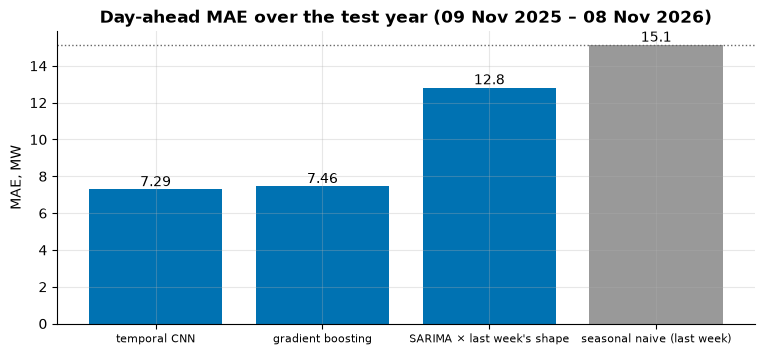

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
viz.bar_scores(result["MAE (MW)"].to_dict(), baseline=base_name, ax=ax, unit="MAE, MW",
               title=f"Day-ahead MAE over the test year ({test.index[0]:%d %b %Y} – {test.index[-1]:%d %b %Y})")
ax.tick_params(axis="x", labelsize=8)

**Where does the error live?** By month, and on public holidays:

,holidays,other days
seasonal naive (last week),52.6,14.2
SARIMA × last week's shape,45.8,12.0
gradient boosting,8.4,7.4
temporal CNN,9.9,7.2


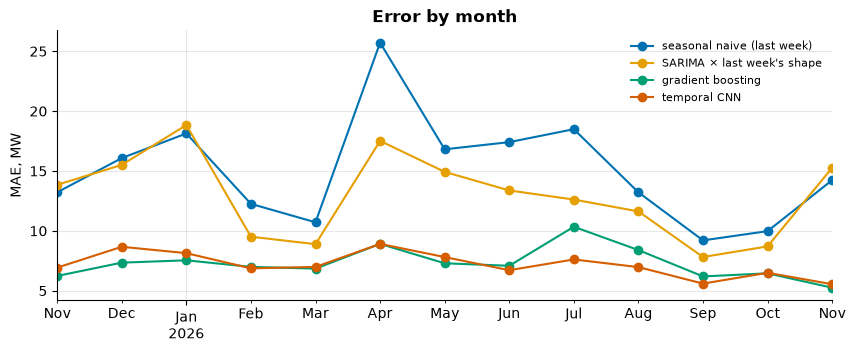

In [8]:
err = pd.DataFrame(daily_err, index=test.index)
monthly = err.groupby(err.index.to_period("M")).mean()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, marker="o")
ax.set(ylabel="MAE, MW", xlabel="", title="Error by month")
ax.legend(fontsize=8)

is_hol = np.isin(test.index.date, list(holidays))
pd.DataFrame({"holidays": err[is_hol].mean(), "other days": err[~is_hol].mean()}).round(1)

## Recorded

The numbers go to `results.json` beside this notebook, and to the run log (`ds_toolbox.tracking`:
MLflow when installed, JSON in `runs/` otherwise).

In [9]:
best = result.index[0]
summary = {
    "challenge": "swiss-forecast",
    "data": "ewz Stadt Zürich, hourly, NE5 + NE7",
    "test_period": [str(test.index[0].date()), str(test.index[-1].date())],
    "metric": "MAE, MW, day-ahead, 24 hours per day",
    "baseline": base_name,
    "results": {m: {"mae_mw": round(float(r["MAE (MW)"]), 3),
                    "skill_vs_baseline": round(float(r["skill vs last week"]), 3)}
                for m, r in result.iterrows()},
    "best": best,
}
here = Path.cwd()
(here / "results.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
tracking.log_run("swiss-forecast", {"test_start": str(test.index[0].date()), "models": len(preds)},
                 {m.split(" ")[0]: v["mae_mw"] for m, v in summary["results"].items()}, root=here,
                 use_mlflow=False)
print(json.dumps(summary["results"], indent=2, ensure_ascii=False))

{
  "temporal CNN": {
    "mae_mw": 7.285,
    "skill_vs_baseline": 0.519
  },
  "gradient boosting": {
    "mae_mw": 7.455,
    "skill_vs_baseline": 0.507
  },
  "SARIMA × last week's shape": {
    "mae_mw": 12.817,
    "skill_vs_baseline": 0.153
  },
  "seasonal naive (last week)": {
    "mae_mw": 15.134,
    "skill_vs_baseline": 0.0
  }
}


## What the number says

The answer is the table above; the conclusions, read off it:

- **Both learned models halve the baseline's error** on a year they never saw. Their gain per
  day has a bootstrap interval well clear of zero, and they beat "the same day last week" on
  about four days in five.
- **Between the two, there is no winner to declare.** The CNN is a little ahead on the test
  year, gradient boosting was a little ahead on the validation year (chapter 6). The gap between
  them is a tenth of their gap to the baseline.
- **SARIMA helps, but far less**: the daily level is not where most of the error is, and within
  a week its forecasts run up to 7 days ahead.
- **Holidays are where the baseline breaks**: about 50 MW of error against 14 on other days,
  because last week was a working week. The learned models know the calendar and bring holidays
  down to almost an ordinary day.

**Back to the book:** [Book 21 · Time Series](../README.md)